# Actividad 8 — Clasificación *Estudiante* vs *Fondo* con VGG-16 (Transfer Learning)

Adaptación del notebook de perros y gatos. Ahora las etiquetas son:

- **Label 1:** nombre del estudiante (carpeta `dataset/<TuNombre>`)
- **Label 2:** `Fondo` (carpeta `dataset/Fondo`: paisajes, habitaciones, objetos **y rostros de otras personas**)

Mejoras respecto al notebook original:

1. **Recorte de rostro** con OpenCV (Haar cascade) antes de clasificar, para que el modelo se fije en la cara y no en la pared de tu cuarto.
2. **`preprocess_input` de VGG-16** (el original pasaba píxeles 0–255 crudos, por eso la *loss* inicial era ~40).
3. Conversión **BGR → RGB** (VGG-16 fue entrenada con RGB).
4. **Aumento de datos** (giros, rotaciones, zoom, contraste) dentro del modelo.
5. **Pesos por clase** por si hay más fotos de una clase que de otra.
6. Guardado en formato nativo `.keras` + `clases.json` para la app de Streamlit.

### Estructura esperada
```
Actividad 8/
├── dataset/
│   ├── Joel/     <- tus fotos (renombra la carpeta con tu nombre)
│   └── Fondo/    <- fondos + caras de otras personas
├── utils.py
└── app.py
```

In [1]:
# Ejecutar solo la primera vez
# %pip install -r requirements.txt

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.applications import VGG16
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

from utils import (preparar_imagen, a_tensor, leer_imagen, guardar_clases,
                   EXTENSIONES, USAR_RECORTE_ROSTRO)

keras.utils.set_random_seed(42)

## 1. Cargar las imágenes

Las clases se toman de los nombres de las subcarpetas de `dataset/`. Se recomiendan **≥ 150 fotos tuyas** variadas y **≥ 300 de Fondo** (mezcla de lugares/objetos y caras de otras personas; usa `descargar_rostros.py`).

In [3]:
DATASET = 'dataset'
CLASES = sorted(d for d in os.listdir(DATASET) if os.path.isdir(os.path.join(DATASET, d)))
print('Clases:', CLASES)
assert 'Fondo' in CLASES and len(CLASES) == 2, 'Debe haber exactamente 2 carpetas: Fondo y tu nombre'

def load_images(carpeta, etiqueta):
    images, labels, con_rostro = [], [], 0
    for nombre in os.listdir(carpeta):
        if not nombre.lower().endswith(EXTENSIONES):
            continue
        img = leer_imagen(os.path.join(carpeta, nombre))
        if img is None:
            continue
        img, hay_rostro = preparar_imagen(img)
        con_rostro += hay_rostro
        images.append(img)
        labels.append(etiqueta)
    return images, labels, con_rostro

images, labels = [], []
for i, clase in enumerate(CLASES):
    imgs, labs, n_rostro = load_images(os.path.join(DATASET, clase), i)
    images += imgs
    labels += labs
    print(f'{clase:>10}: {len(imgs)} imágenes (rostro detectado en {n_rostro})')

images = np.array(images)
labels = np.array(labels)

Clases: ['Fondo', 'Joel']


     Fondo: 723 imágenes (rostro detectado en 465)


      Joel: 395 imágenes (rostro detectado en 392)


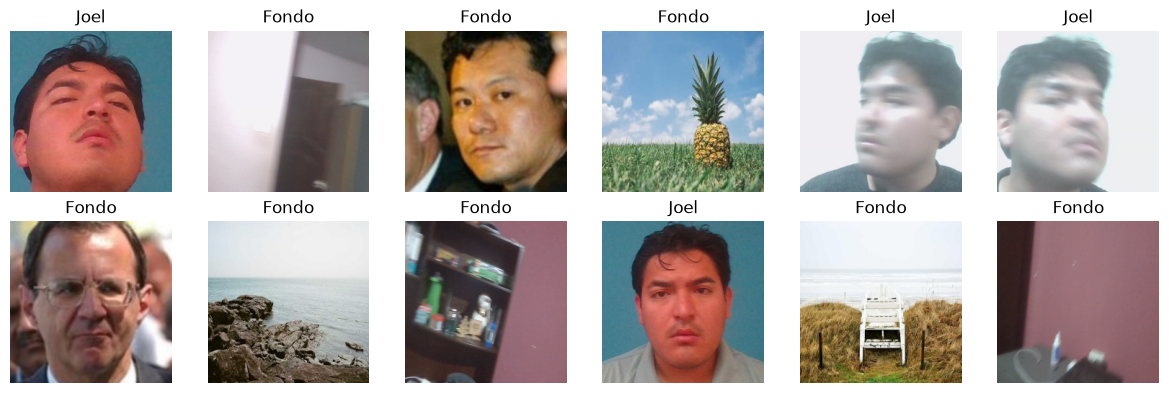

In [4]:
# Vistazo a lo que realmente verá el modelo (rostros recortados)
idx = np.random.choice(len(images), 12, replace=False)
plt.figure(figsize=(12, 4))
for k, i in enumerate(idx):
    plt.subplot(2, 6, k + 1)
    plt.imshow(images[i])
    plt.title(CLASES[labels[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. One-hot encoding y división entrenamiento / prueba

In [5]:
X = a_tensor(images)                    # normalización de VGG-16
y = to_categorical(labels, num_classes=len(CLASES))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=labels, random_state=42)

pesos = compute_class_weight('balanced', classes=np.arange(len(CLASES)), y=labels)
class_weight = dict(enumerate(pesos))
print('Train:', X_train.shape, ' Test:', X_test.shape, ' class_weight:', class_weight)

Train: (894, 224, 224, 3)  Test: (224, 224, 224, 3)  class_weight: {0: np.float64(0.7731673582295989), 1: np.float64(1.4151898734177215)}


## 3. Modelo VGG-16 + cabeza personalizada

Hiperparámetros que puedes probar (parte opcional de la actividad): `AUMENTO`, `LOSS`, `OPTIMIZER`, `EPOCHS`, `BATCH_SIZE`.

In [6]:
# ---------- Hiperparámetros ----------
AUMENTO = True
LOSS = 'categorical_crossentropy'
OPTIMIZER = keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 25
BATCH_SIZE = 16
# -------------------------------------

aumento = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.3, value_range=(-124.0, 152.0)),  # imagen ya normalizada por VGG-16
], name='aumento')

baseModel = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
baseModel.trainable = False   # congelamos las capas convolucionales

model = keras.Sequential(name='vgg16_rostro_fondo')
model.add(keras.Input(shape=(224, 224, 3)))
if AUMENTO:
    model.add(aumento)        # solo actúa durante el entrenamiento
model.add(baseModel)
model.add(layers.GlobalAveragePooling2D())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(len(CLASES), activation='softmax'))

model.compile(loss=LOSS, optimizer=OPTIMIZER, metrics=['accuracy'])
model.summary()

Model: "vgg16_rostro_fondo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,530 (56.64 MB)

 Trainable params: 131,842 (515.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [7]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('modelo_rostro_fondo.keras', monitor='val_loss', save_best_only=True),
]

history = model.fit(X_train, y_train,
                    validation_data=(X_test, y_test),
                    epochs=EPOCHS, batch_size=BATCH_SIZE,
                    class_weight=class_weight, callbacks=callbacks)

Epoch 1/25


 1/56 ━━━━━━━━━━━━━━━━━━━━ 3:26 4s/step - accuracy: 0.5625 - loss: 2.5798

 2/56 ━━━━━━━━━━━━━━━━━━━━ 1:42 2s/step - accuracy: 0.3750 - loss: 3.1809

 3/56 ━━━━━━━━━━━━━━━━━━━━ 1:42 2s/step - accuracy: 0.3125 - loss: 3.8776

 4/56 ━━━━━━━━━━━━━━━━━━━━ 1:44 2s/step - accuracy: 0.3125 - loss: 3.3869

 5/56 ━━━━━━━━━━━━━━━━━━━━ 1:43 2s/step - accuracy: 0.3125 - loss: 3.2485

... (1,440 outputs left out)

54/56 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.9850 - loss: 0.0490

55/56 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.9841 - loss: 0.0491

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9843 - loss: 0.0484

56/56 ━━━━━━━━━━━━━━━━━━━━ 171s 3s/step - accuracy: 0.9843 - loss: 0.0484 - val_accuracy: 1.0000 - val_loss: 0.0133


### 3.1 (Opcional) Fine-tuning del último bloque de VGG-16
Descongela `block5` y entrena unas épocas más con una tasa de aprendizaje muy baja. Suele mejorar la distinción entre tu cara y caras parecidas (prueba 3).

In [8]:
FINE_TUNING = True

if FINE_TUNING:
    baseModel.trainable = True
    for layer in baseModel.layers:
        layer.trainable = layer.name.startswith('block5')
    model.compile(loss=LOSS, optimizer=keras.optimizers.Adam(1e-5), metrics=['accuracy'])
    history_ft = model.fit(X_train, y_train,
                           validation_data=(X_test, y_test),
                           epochs=8, batch_size=BATCH_SIZE,
                           class_weight=class_weight, callbacks=callbacks)

Epoch 1/8


 1/56 ━━━━━━━━━━━━━━━━━━━━ 5:01 5s/step - accuracy: 1.0000 - loss: 0.0058

 2/56 ━━━━━━━━━━━━━━━━━━━━ 2:22 3s/step - accuracy: 1.0000 - loss: 0.0261

 3/56 ━━━━━━━━━━━━━━━━━━━━ 2:28 3s/step - accuracy: 1.0000 - loss: 0.0181

 4/56 ━━━━━━━━━━━━━━━━━━━━ 2:28 3s/step - accuracy: 1.0000 - loss: 0.0173

 5/56 ━━━━━━━━━━━━━━━━━━━━ 2:25 3s/step - accuracy: 0.9875 - loss: 0.0359

... (454 outputs left out)

54/56 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step - accuracy: 0.9965 - loss: 0.0069

55/56 ━━━━━━━━━━━━━━━━━━━━ 2s 3s/step - accuracy: 0.9966 - loss: 0.0072

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9966 - loss: 0.0071

56/56 ━━━━━━━━━━━━━━━━━━━━ 201s 4s/step - accuracy: 0.9966 - loss: 0.0071 - val_accuracy: 1.0000 - val_loss: 0.0011


## 4. Evaluación

Loss: 0.0011
Accuracy: 1.0000


              precision    recall  f1-score   support

       Fondo       1.00      1.00      1.00       145
        Joel       1.00      1.00      1.00        79

    accuracy                           1.00       224
   macro avg       1.00      1.00      1.00       224
weighted avg       1.00      1.00      1.00       224



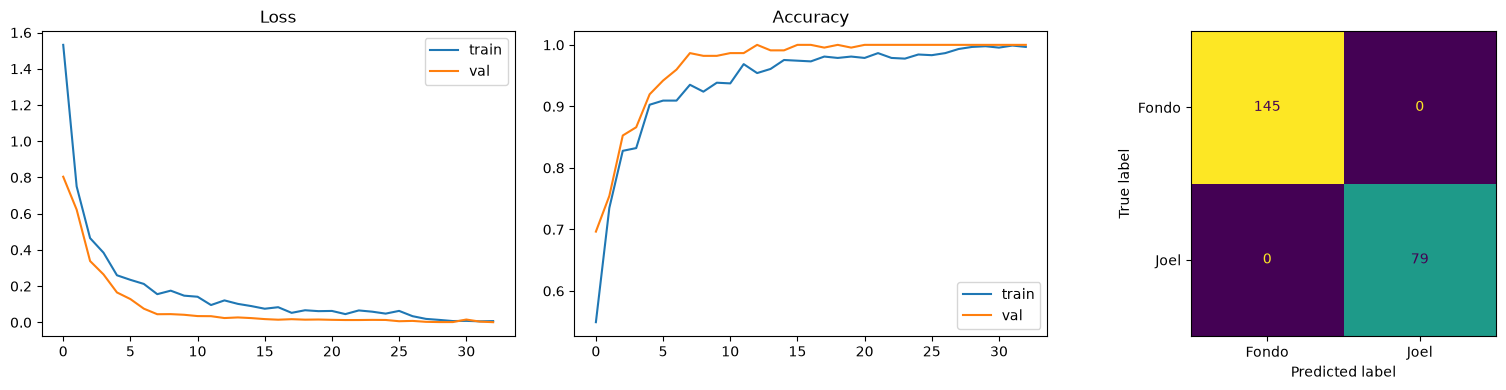

In [9]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Loss: {loss:.4f}')
print(f'Accuracy: {accuracy:.4f}')

y_pred = model.predict(X_test, verbose=0).argmax(1)
y_true = y_test.argmax(1)
print(classification_report(y_true, y_pred, target_names=CLASES))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
h = history.history
if FINE_TUNING:
    h = {k: h[k] + history_ft.history[k] for k in h}
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASES, ax=ax[2], colorbar=False)
plt.tight_layout()
plt.show()

## 5. Guardar el modelo y las clases

In [10]:
model.save('modelo_rostro_fondo.keras')
guardar_clases(CLASES)
print('Guardado: modelo_rostro_fondo.keras y clases.json')

Guardado: modelo_rostro_fondo.keras y clases.json


## 6. Las 3 pruebas

Coloca las imágenes de prueba (que **no** estén en `dataset/`) en la carpeta `pruebas/` y ejecuta la celda. En clase usarás la app: `streamlit run app.py`.

| Prueba | Imagen | Salida requerida |
|---|---|---|
| 1 | Tu foto tomada con la webcam el día de la presentación | Tu nombre |
| 2 | Fondo descargado con la palabra que te den | `Fondo` |
| 3 | Celebridad parecida a ti | `Fondo` |

In [11]:
from keras.models import load_model
from utils import cargar_clases

model = load_model('modelo_rostro_fondo.keras')
CLASES = cargar_clases()

def predecir(ruta):
    img, hay_rostro = preparar_imagen(leer_imagen(ruta))
    pred = model.predict(a_tensor(img), verbose=0)[0]
    return img, hay_rostro, pred

CARPETA_PRUEBAS = 'pruebas'
archivos = [f for f in sorted(os.listdir(CARPETA_PRUEBAS)) if f.lower().endswith(EXTENSIONES)] if os.path.isdir(CARPETA_PRUEBAS) else []

for f in archivos:
    img, hay_rostro, pred = predecir(os.path.join(CARPETA_PRUEBAS, f))
    etiqueta = CLASES[pred.argmax()]
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(f'{etiqueta} ({pred.max():.1%})')
    plt.axis('off')
    plt.show()
    print(f, '->', dict(zip(CLASES, np.round(pred, 3))), '| rostro detectado:', hay_rostro)